
# 28 期权价差与组合套利：逐腿算账

> **本章要解决的问题**：一个四腿组合，到底赚什么钱？为什么中间价加总是“负支出”，实盘却不一定是套利？逐腿成交、深度、费用，怎样把理论价差变成可执行价差？

## 本章导读

第24章讲了单腿期权，第27章讲了对冲。这一章讲**多腿组合**：价差、跨式、蝶式、箱式。

本章分五节：

1. 逐腿损益：斜率、拐点、分段；
2. 垂直价差、跨式、蝶式、箱式；
3. 无套利：凸性、箱式平价；
4. 逐腿成交：买卖价、深度、费用；
5. 行权/指派/融资的实务。

### 学习目标

- 能画出两腿/三腿/四腿组合的到期损益。
- 会算垂直价差、跨式、蝶式、箱式的支付。
- 能解释蝶式凸性与箱式平价。
- 会用逐腿 bid/ask 算可执行净支出。
- 能判断“中间价套利”是否可执行，并列出指派风险。

### 先修

第24章的支付/平价；第26章的隐波；会 numpy。

---

### 环境准备



## 本章知识结构图

<svg style="max-width:100%;height:auto" xmlns="http://www.w3.org/2000/svg" width="800" height="450" viewBox="0 0 800 450" role="img" aria-label="28 期权价差与组合套利：逐腿算账" font-family="Microsoft YaHei, SimHei, sans-serif">
<title>28 期权价差与组合套利：逐腿算账｜知识图</title>
<desc>本章主线：每个执行价都是斜率拐点；中间价加总的“套利”，要用逐腿 bid/ask 重新算。</desc>
<rect x="0" y="0" width="800" height="450" fill="#FFFFFF"/>
<defs><marker id="a25" viewBox="0 0 10 10" refX="9" refY="5" markerWidth="7" markerHeight="7" orient="auto-start-reverse"><path d="M0,0 L10,5 L0,10 Z" fill="#1B3A5C"/></marker><marker id="ao25" viewBox="0 0 10 10" refX="9" refY="5" markerWidth="7" markerHeight="7" orient="auto-start-reverse"><path d="M0,0 L10,5 L0,10 Z" fill="#E07B39"/></marker><marker id="ag25" viewBox="0 0 10 10" refX="9" refY="5" markerWidth="7" markerHeight="7" orient="auto-start-reverse"><path d="M0,0 L10,5 L0,10 Z" fill="#6E7B8B"/></marker></defs>
<rect x="40" y="19" width="46" height="29" fill="#E07B39" rx="8"/>
<text x="63" y="39" font-size="15" fill="#FFFFFF" text-anchor="middle" font-weight="bold">28</text>
<text x="98" y="41" font-size="22" fill="#1B3A5C" font-weight="bold">期权价差与组合套利：逐腿算账</text>
<line x1="40" y1="57" x2="760" y2="57" stroke="#E6EFF7" stroke-width="2" stroke-linecap="round"/>
<line x1="40" y1="407" x2="760" y2="407" stroke="#E6EFF7" stroke-width="1.6" stroke-linecap="round"/>
<rect x="40" y="418" width="4" height="10" fill="#E07B39" rx="1"/>
<text x="52" y="428" font-size="13" fill="#6E7B8B">本章主线：每个执行价都是斜率拐点；中间价加总的“套利”，要用逐腿 bid/ask 重新算。</text>
<rect x="45" y="82" width="400" height="250" fill="#FFFFFF" stroke="#E6EFF7" stroke-width="1.5" rx="14"/>
<text x="60" y="102" font-size="10.5" fill="#1B3A5C" font-weight="bold">① 垂直价差：到期损益</text>
<path d="M 65 280 L 430 280" fill="none" stroke="#6E7B8B" stroke-width="1.3" stroke-linecap="round" stroke-linejoin="round" marker-end="url(#ag25)"/>
<path d="M 65 280 L 65 280" fill="none" stroke="#6E7B8B" stroke-width="1.3" stroke-linecap="round" stroke-linejoin="round" marker-end="url(#ag25)"/>
<text x="72" y="134" font-size="9" fill="#6E7B8B">P&amp;L</text>
<text x="414" y="298" font-size="9" fill="#6E7B8B">S_T</text>
<line x1="70" y1="240" x2="428" y2="240" stroke="#E6EFF7" stroke-width="1.2" stroke-linecap="round"/>
<line x1="215" y1="240" x2="215" y2="286" stroke="#6E7B8B" stroke-width="1" stroke-linecap="round" stroke-dasharray="4 3"/>
<text x="215" y="300" font-size="8.6" fill="#6E7B8B" text-anchor="middle">K1=100</text>
<line x1="285" y1="240" x2="285" y2="286" stroke="#6E7B8B" stroke-width="1" stroke-linecap="round" stroke-dasharray="4 3"/>
<text x="285" y="300" font-size="8.6" fill="#6E7B8B" text-anchor="middle">K2=110</text>
<path d="M 75 260 L 215 260 L 285 180 L 425 180" fill="none" stroke="#1B3A5C" stroke-width="2.4" stroke-linecap="round" stroke-linejoin="round"/>
<line x1="75" y1="260" x2="215" y2="260" stroke="#E07B39" stroke-width="1.3" stroke-linecap="round" stroke-dasharray="4 3"/>
<text x="150" y="254" font-size="8.8" fill="#E07B39">最大亏损 −2.5（净支出）</text>
<line x1="285" y1="180" x2="425" y2="180" stroke="#1B3A5C" stroke-width="1.1" stroke-linecap="round" stroke-dasharray="4 3"/>
<text x="300" y="172" font-size="8.6" fill="#1B3A5C">最大盈利 +7.5 = K2 − K1 − 净支出</text>
<text x="75" y="324" font-size="9" fill="#6E7B8B">净支出 2.5：到期损益 = 两腿支付 − 净支出</text>
<rect x="465" y="82" width="290" height="250" fill="#FFFFFF" stroke="#E6EFF7" stroke-width="1.5" rx="14"/>
<text x="480" y="102" font-size="10.5" fill="#1B3A5C" font-weight="bold">② 逐腿组合（示例蝶式）</text>
<rect x="480" y="112" width="122" height="50" fill="#E6EFF7" stroke="#1B3A5C" stroke-width="1.5" rx="14"/>
<text x="541" y="129.4" font-size="10.2" fill="#1B3A5C" text-anchor="middle" font-weight="bold">买 K1 Call</text>
<text x="541" y="147" font-size="8.2" fill="#6E7B8B" text-anchor="middle">权利金 6.0</text>
<rect x="612" y="112" width="122" height="50" fill="#E6EFF7" stroke="#1B3A5C" stroke-width="1.5" rx="14"/>
<text x="673" y="129.4" font-size="10.2" fill="#1B3A5C" text-anchor="middle" font-weight="bold">卖 K2 Call</text>
<text x="673" y="147" font-size="8.2" fill="#6E7B8B" text-anchor="middle">权利金 3.0</text>
<rect x="480" y="174" width="122" height="50" fill="#E6EFF7" stroke="#1B3A5C" stroke-width="1.5" rx="14"/>
<text x="541" y="191.4" font-size="10.2" fill="#1B3A5C" text-anchor="middle" font-weight="bold">买 K3 Call</text>
<text x="541" y="209" font-size="8.2" fill="#6E7B8B" text-anchor="middle">权利金 2.2</text>
<rect x="612" y="174" width="122" height="50" fill="#E6EFF7" stroke="#1B3A5C" stroke-width="1.5" rx="14"/>
<text x="673" y="191.4" font-size="10.2" fill="#1B3A5C" text-anchor="middle" font-weight="bold">卖 K4 Call</text>
<text x="673" y="209" font-size="8.2" fill="#6E7B8B" text-anchor="middle">权利金 1.1</text>
<rect x="480" y="250" width="254" height="56" fill="#1B3A5C" stroke="#1B3A5C" stroke-width="1.5" rx="14"/>
<text x="607" y="270.4" font-size="10.8" fill="#FFFFFF" text-anchor="middle" font-weight="bold">净支出与最大盈亏</text>
<text x="607" y="288.4" font-size="8.6" fill="#FFFFFF" text-anchor="middle">逐腿 bid/ask 才算得准</text>
<path d="M 541 162 L 607 250" fill="none" stroke="#6E7B8B" stroke-width="1" stroke-linecap="round" stroke-linejoin="round" stroke-dasharray="3 3" marker-end="url(#ag25)"/>
<path d="M 673 162 L 607 250" fill="none" stroke="#6E7B8B" stroke-width="1" stroke-linecap="round" stroke-linejoin="round" stroke-dasharray="3 3" marker-end="url(#ag25)"/>
<path d="M 541 224 L 607 250" fill="none" stroke="#6E7B8B" stroke-width="1" stroke-linecap="round" stroke-linejoin="round" stroke-dasharray="3 3" marker-end="url(#ag25)"/>
<path d="M 673 224 L 607 250" fill="none" stroke="#6E7B8B" stroke-width="1" stroke-linecap="round" stroke-linejoin="round" stroke-dasharray="3 3" marker-end="url(#ag25)"/>
<text x="480" y="320" font-size="8.8" fill="#E07B39">中间价净支出 2.5 → 逐腿 bid/ask 3.4</text>
<text x="45" y="366" font-size="9.2" fill="#6E7B8B">蝶式：K1 &lt; K2 &lt; K3；箱式平价与凸性检查无套利</text>
<text x="45" y="384" font-size="9.2" fill="#6E7B8B">实盘：一档报价 × 全部数量 = 高估可成交性</text>
</svg>

> **图**：本章主线：每个执行价都是斜率拐点；中间价加总的“套利”，要用逐腿 bid/ask 重新算。


In [1]:

import matplotlib.pyplot as plt

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
print("matplotlib 中文字体已设置")


matplotlib 中文字体已设置



## 在量化研究中的位置

- **谁用**：期权交易员、做市、相对价值。
- **输入**：各腿 bid/ask、深度、手续费、行权规则。
- **输出**：到期损益、可执行净支出、无套利检查、最大亏损。
- **在流程的哪一步**：多腿组合与套利。
- **失败模式**：中间价算利润、一档报价乘全部数量、忽略指派。
- **最小工作流**：逐腿报价 → 支付形状 → 蝶式/箱式 → 可执行成本 → 行权/指派检查。

---
## 1. 逐腿损益：斜率、拐点、分段

### 1.1 看涨的斜率

到期支付：

$$\max(S_T-K,0).$$

- $S_T<K$：斜率 0；
- $S_T>K$：斜率 1。

每个执行价都是一个“斜率改变点”（拐点）。多腿组合的损益，就是这些分段直线的叠加。

### 1.2 垂直价差

买低执行价看涨、卖高执行价看涨：

$$\text{payoff}=\max(S-K_1,0)-\max(S-K_2,0)-\text{net premium}.$$

- 低于 $K_1$：0；
- 高于 $K_2$：$K_2-K_1$；
- 中间：线性上升。

**公式拆解**
- **符号**：$S$ 到期标的价，$K_1<K_2$ 执行价，net premium 为净支出（元/吨）。
- **结构**：支付 $\max(S-K_1,0)-\max(S-K_2,0)$ 是 0 到 $K_2-K_1$ 的斜坡，再减净支出。
- **代入**：买 95、卖 105 看涨、净付 4：$S=100$ 时 $5-0-4=1$；最大亏 4，最大盈 6，平衡点 99。
- **边界**：$S\le K_1$ 恒为 $-$net；$S\ge K_2$ 封顶 $K_2-K_1-$net。
- **用途**：表达温和看涨、有限风险；别忘扣净权利金，方向对不一定赚。

### 1.3 代码：牛市价差



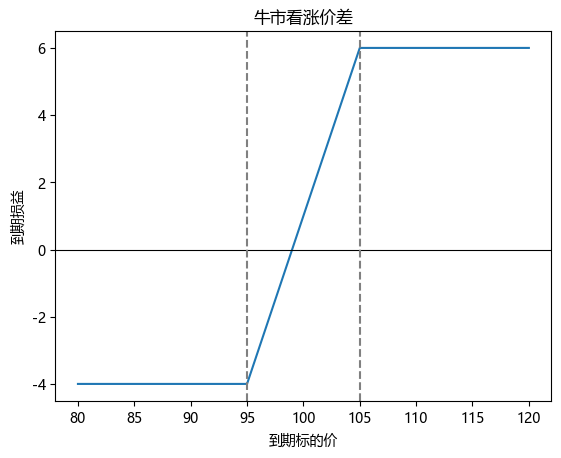

S=90/100/110 的损益 [-4.  1.  6.]


In [2]:

import numpy as np
import matplotlib.pyplot as plt

S = np.linspace(80, 120, 41)
K1, K2, premium = 95.0, 105.0, 4.0

payoff = np.maximum(S - K1, 0) - np.maximum(S - K2, 0) - premium
plt.plot(S, payoff)
plt.axhline(0, color="black", linewidth=0.8)
plt.axvline(K1, color="grey", linestyle="--")
plt.axvline(K2, color="grey", linestyle="--")
plt.xlabel("到期标的价")
plt.ylabel("到期损益")
plt.title("牛市看涨价差")
plt.show()

print("S=90/100/110 的损益", payoff[[10, 20, 30]].round(2))



**读数与应用**：最大亏损 4（净权利金），最大盈利 $10-4=6$，盈亏平衡 $95+4=99$。

**常见错误**：

1. 把“最大盈利”算成 $K_2-K_1$，忘记扣净权利金。
2. 买卖方向写反，变成熊市价差。
3. 不画图，只看两个端点。

**停下来想一想**：牛市价差和单腿看涨，最大区别是什么？

<details><summary>对照你的思路</summary>

牛市价差卖出了高执行价看涨，放弃了上方无限收益，换来更低的成本/更小的最大亏损。它是“有限风险、有限收益”的结构；单腿看涨是“有限风险、无限收益”，但权利金更贵。

</details>

---



## 2. 跨式、蝶式、箱式

### 2.1 跨式

买同行权价的看涨 + 看跌：

$$\text{payoff}=|S_T-K|-\text{premium}.$$

观点：大波动，方向不限；怕横盘（时间价值损耗）。

### 2.2 蝶式

买 $K_1$ 看涨、卖两份 $K_2$ 看涨、买 $K_3$ 看涨（等距）：

- 两端支付 0；
- 中间 $K_2$ 处支付最大 $K_2-K_1$；
- 形状是“帐篷”。

蝶式是“押注标的停在 $K_2$ 附近”的结构；也是凸性/无套利检验的工具。

### 2.3 箱式

牛市看涨价差 + 熊市看跌价差，合起来在各状态支付固定 $K_2-K_1$：

$$\text{box payoff}=K_2-K_1.$$

若今天价格不等于贴现后的 $K_2-K_1$，存在套利（忽略成本）。

### 2.4 代码：跨式与蝶式



In [3]:

strike, premium = 100.0, 8.0
straddle = np.abs(S - strike) - premium

K1, K2, K3 = 90.0, 100.0, 110.0
butterfly = (np.maximum(S - K1, 0) - 2 * np.maximum(S - K2, 0)
             + np.maximum(S - K3, 0) - 2.0)

print("跨式 S=90/100/110", straddle[[10, 20, 30]].round(2))
print("蝶式 S=90/100/110", butterfly[[10, 20, 30]].round(2))


跨式 S=90/100/110 [ 2. -8.  2.]
蝶式 S=90/100/110 [-2.  8. -2.]



**读数与应用**：跨式在 90/110 的损益为 2，在 100 为 −8；蝶式在 90/110 为 −2，在 100 为 8。两者的“观点”相反：跨式押大动，蝶式押不动。

**常见错误**：

1. 蝶式的中间腿卖 1 份而不是 2 份；支付形状不对。
2. 跨式忘记两份权利金。
3. 把蝶式当“无风险套利”；它仍有方向/时间风险。

**停下来想一想**：蝶式为什么常用来检查无套利？

<details><summary>对照你的思路</summary>

蝶式的支付非负（帐篷形），所以今天价格必须非负；若蝶式价格为负，等于“别人付钱让你持有非负支付”，就是套利。蝶式价格非负，等价于看涨价对执行价凸。

</details>

---



## 3. 无套利：凸性与箱式平价

### 3.1 蝶式非负

等距蝶式的到期支付非负，所以今天价格必须非负：

$$\text{Butterfly}=C(K_1)-2C(K_2)+C(K_3)\ge0.$$

这等价于看涨价对执行价凸：

$$\frac{\partial^2C}{\partial K^2}\ge0.$$

**公式拆解**
- **符号**：$C(K_i)$ 为同到期看涨价，$K_1<K_2<K_3$ 等距。
- **结构**：$C(K_1)-2C(K_2)+C(K_3)$ 是二阶差分，支付为帐篷形非负，故价格 $\ge0$。
- **代入**：$K=90,100,110$ 的价格 $11.78,5.58,2.10$：$11.78-11.16+2.10=2.72>0$。
- **边界**：$\sigma\to0$ 时蝶式趋 0；中腿必须是 2 份，负值先查报价。
- **用途**：曲面清洗与无套利检查；蝶式非负是必要条件，不保证整面可套利。

### 3.2 箱式平价

箱式 = 牛市看涨价差 + 熊市看跌价差，到期固定支付 $K_2-K_1$：

$$\text{Box}=[C(K_1)-C(K_2)]+[P(K_2)-P(K_1)]=(K_2-K_1)e^{-rT}.$$

若市场价格偏离，存在套利（忽略成本/行权/融资）。

**公式拆解**
- **符号**：$C(K_i),P(K_i)$ 为同到期看涨/看跌价，$r$ 利率，$T$ 年。
- **结构**：箱式=牛市看涨价差+熊市看跌价差，到期固定支付 $K_2-K_1$，现值 $(K_2-K_1)e^{-rT}$。
- **代入**：$K_1=95,K_2=105,r=2\%,T=0.25$：$10\times e^{-0.005}\approx9.95$；净支出 9.5 则差 0.45。
- **边界**：$r=0$ 或 $T\to0$ 时等于 $K_2-K_1$；美式与指派只给不等式。
- **用途**：查看涨/看跌相对定价；不是无风险，价差会吃掉偏离。

### 3.3 代码：箱式理论价



In [4]:

import numpy as np

K1, K2, r, T = 95.0, 105.0, 0.02, 0.25
box_value = (K2 - K1) * np.exp(-r * T)
print("箱式理论现值", round(box_value, 4))


箱式理论现值 9.9501



**读数与应用**：理论箱式价值约 9.95；若市场四腿净支出明显低于它，可能有机会，但要逐腿成交/费用/行权。

**常见错误**：

1. 把箱式当“无风险”，忽略逐腿成交和指派。
2. 用欧式平价套美式期权。
3. 忘了贴现。

**停下来想一想**：为什么箱式偏离不一定是套利？

<details><summary>对照你的思路</summary>

因为四腿要同时成交，买卖价差、深度、手续费、行权/指派、资金占用都会吃掉偏离；美式期权还可能提前行权/被指派。理论偏离只是“候选”，不是“可执行套利”。

</details>

---



## 4. 逐腿成交：买卖价、深度、费用

### 4.1 中间价 vs 可执行价

中间价加总：

$$\text{mid}=\frac{\text{bid}+\text{ask}}{2}.$$

但买入按 ask、卖出按 bid。四腿组合的可执行净支出，要把每条腿的方向和买卖价代进去。

**公式拆解**
- **符号**：bid/ask 为各腿买价/卖价，$w_i$ 为方向（$+1$ 买、$-2$ 卖两份）。
- **结构**：mid$=(\text{bid}+\text{ask})/2$；可执行净支出买付 ask、卖收 bid。
- **代入**：bid$=(12.8,9.1,5.8)$、ask$=(13.2,9.5,6.2)$：mid 净支出 0.4，逐腿可执行 1.2，差 0.8。
- **边界**：无价差时相等；深度不足或 bid 为 0 时不可执行。
- **用途**：理论价差变可执行价差；mid 不是可成交价。

### 4.2 深度

中间腿可能只有 1 手深度；要卖 2 手，第二手要打到更差的价位。用“逐档盘口”算，不要用一档报价乘数量。

### 4.3 代码：逐腿成本



In [5]:

import numpy as np

bids = np.array([12.8, 9.1, 5.8])
asks = np.array([13.2, 9.5, 6.2])
weights = np.array([1, -2, 1])

mid = (bids + asks) / 2
mid_cost = mid @ weights
exec_cost = asks[0] + asks[2] - 2 * bids[1]

print("中间价净支出", round(mid_cost, 3))
print("逐腿可执行净支出", round(exec_cost, 3))
print("差额", round(exec_cost - mid_cost, 3))


中间价净支出 0.4
逐腿可执行净支出 1.2
差额 0.8



**读数与应用**：中间价 0.4，逐腿可执行 1.2，差 0.8。若策略的“利润”只有 0.5，价差就把它吃掉了。

**常见错误**：

1. 中间价算利润，市价单成交。
2. 用一档报价乘全部数量，忽略深度。
3. 只算手续费，不算价差。

**停下来想一想**：为什么“负支出”的蝶式不一定是套利？

<details><summary>对照你的思路</summary>

负支出意味着“开仓就收钱”，但如果四腿不能同时成交、中间腿深度不够、手续费/保证金/指派风险存在，最终可能不是无风险利润。要按逐腿可执行价和最坏情况算。

</details>

---



## 5. 行权、指派、融资的实务

### 5.1 指派

卖方在到期前可能被指派；指派是随机的，不一定按开仓顺序。被指派后，你要按执行价买入/卖出标的，可能产生期货持仓/保证金。

### 5.2 行权

美式期权可以提前行权；实值期权在到期日可能被自动行权。行权后，组合的腿数/风险会变，不是“自动平仓”。

### 5.3 融资/保证金

多腿组合的保证金可能按“组合保证金”算，也可能按“逐腿”算；不同柜台/交易所规则不同。资金占用会影响可执行规模。

### 5.4 检查清单

- [ ] 每条腿的方向/买卖价/数量；
- [ ] 深度/逐档盘口；
- [ ] 手续费/滑点；
- [ ] 行权/指派规则；
- [ ] 保证金/资金占用；
- [ ] 最坏情况下的最大亏损。

**常见错误**：

1. 把“组合保证金”当“无保证金”。
2. 忽略指派后的期货持仓。
3. 用欧式规则套美式期权。

**停下来想一想**：为什么多腿组合的“最大亏损”不能只看到期支付图？

<details><summary>对照你的思路</summary>

到期支付图假设持有到期、按支付结算；但多腿组合可能被提前指派/行权，腿数变化，保证金/资金占用也会变化。最大亏损要考虑“路径中最坏的行权/指派/强平”，不只是到期那一点。

</details>

---



## 本章小结

### 一张表

| 组合 | 支付 | 观点 |
|---|---|---|
| 牛市价差 | 0 到 $K_2-K_1$ | 温和看涨 |
| 跨式 | $\|S-K\|$ | 大波动 |
| 蝶式 | 帐篷 | 停在 $K_2$ |
| 箱式 | 固定 $K_2-K_1$ | 套利/平价 |

### 八句话

1. 每个执行价都是斜率拐点。
2. 垂直价差的最大盈利要扣净权利金。
3. 跨式押大动，蝶式押不动。
4. 蝶式非负等价于看涨价凸。
5. 箱式理论值 $=(K_2-K_1)e^{-rT}$。
6. 中间价不是可成交价。
7. 深度不够时，一档报价不能乘全部数量。
8. 多腿组合的最大亏损要考虑指派/行权/保证金。

---

## 本章习题

**1.** 买 95 看涨、卖 105 看涨，净付 4。求最大亏损、最大盈利、盈亏平衡。

**2.** 买 100 跨式，付 8。到期 90/100/110 的损益？

**3.** 蝶式 90/100/110，净付 2。到期 100 的支付和净损益？

**4.** 箱式 95/105，r=2%，T=0.25。理论现值多少？

**5.** 中间价净支出 0.4，逐腿可执行 1.2。差额多少？

**6.** 为什么蝶式负价格是套利？

**7.** 为什么多腿组合不能只看到期支付图？

**8.** 逐腿成交时，为什么不能用一档报价乘全部数量？

<details><summary>参考答案</summary>

**1.** 最大亏损 4；最大盈利 $10-4=6$；盈亏平衡 $95+4=99$。

**2.** 90：2；100：−8；110：2。

**3.** 100 时蝶式支付 10，净损益 $10-2=8$。

**4.** $10\times e^{-0.02\times0.25}\approx9.95$。

**5.** $1.2-0.4=0.8$。

**6.** 蝶式到期支付非负；负价格等于“别人付钱让你持有非负支付”。

**7.** 可能被提前行权/指派，腿数、保证金、资金占用会变；最大亏损要看路径。

**8.** 盘口深度有限，第二手可能打到更差价位；要逐档算。

</details>

---

## 参考资料

- Hull, J. C. *Options, Futures, and Other Derivatives*（价差/组合）。
- CME Institute, *Options Strategies*。
